In [1]:
import os
import glob
import shutil
import subprocess
import tempfile

# Rutas: las manos de Pluribus se guardan junto al shard de HandHQ
pluribus_dir = "../data/raw/pluribus"
processed_dir = "../data/processed/modelo4"
os.makedirs(pluribus_dir, exist_ok=True)
os.makedirs(processed_dir, exist_ok=True)

# Fuente: repositorio oficial del formato PHH (Universidad de Toronto), carpeta data/pluribus
# Manos originales publicadas por Brown & Sandholm (Science, 2019): 5 profesionales + Pluribus
REPO = "https://github.com/uoftcprg/phh-dataset.git"

archivos = glob.glob(os.path.join(pluribus_dir, "*", "*.phh"))
if len(archivos) == 0:
    print("📥 Descargando las manos de Pluribus (solo la carpeta necesaria, ~12 MB)...")
    assert shutil.which("git"), "Se necesita Git instalado para la descarga"
    temporal = tempfile.mkdtemp()
    subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse", REPO, temporal], check=True)
    subprocess.run(["git", "-C", temporal, "sparse-checkout", "set", "data/pluribus"], check=True)
    shutil.copytree(os.path.join(temporal, "data", "pluribus"), pluribus_dir, dirs_exist_ok=True)
    shutil.rmtree(temporal, ignore_errors=True)
    archivos = glob.glob(os.path.join(pluribus_dir, "*", "*.phh"))
else:
    print("📂 Las manos de Pluribus ya estaban descargadas.")

tamano = sum(os.path.getsize(a) for a in archivos) / 1024**2
print(f"✅ Archivos de manos disponibles: {len(archivos):,} ({tamano:.1f} MB)")
print(f" • Sesiones de juego: {len(set(os.path.basename(os.path.dirname(a)) for a in archivos))}")

📥 Descargando las manos de Pluribus (solo la carpeta necesaria, ~12 MB)...


✅ Archivos de manos disponibles: 10,000 (5.3 MB)
 • Sesiones de juego: 92


In [2]:
import tomllib
import numpy as np
import pandas as pd

# 1. Cada archivo .phh es una mano en formato TOML: se lee como un diccionario
filas = []
for ruta in sorted(archivos):
    with open(ruta, 'rb') as f:
        mano = tomllib.load(f)
    filas.append({
        'sesion': os.path.basename(os.path.dirname(ruta)),
        'archivo': os.path.basename(ruta),
        'players': mano['players'],
        'starting_stacks': mano['starting_stacks'],
        'blinds_or_straddles': mano['blinds_or_straddles'],
        'actions': mano['actions'],
    })
df_manos = pd.DataFrame(filas)
df_manos['hand_key'] = np.arange(len(df_manos))

# 2. Auditoría: ¿realmente se ven las cartas privadas de TODOS los jugadores?
repartos = [a for acts in df_manos['actions'] for a in acts if a.startswith('d dh')]
ocultas = sum('?' in a for a in repartos)

print("=" * 65)
print("  AUDITORÍA DEL DATASET DE PLURIBUS")
print("=" * 65)
print(f" • Manos leídas: {len(df_manos):,}")
print(f" • Jugadores por mesa: {sorted(df_manos['players'].apply(len).unique())}")
print(f" • Ciegas: {sorted(set(tuple(b) for b in df_manos['blinds_or_straddles']))}")
print(f" • Stacks iniciales (fichas): {sorted(set(s for st in df_manos['starting_stacks'] for s in st))} ➔ 100 ciegas grandes")
print(f" • Cartas privadas repartidas: {len(repartos):,} | Ocultas ('????'): {ocultas} ➔ {100 - ocultas / len(repartos) * 100:.1f}% visibles")

print("\n👥 Manos jugadas por cada jugador:")
conteo = pd.Series([p for ps in df_manos['players'] for p in ps]).value_counts()
for jugador, n in conteo.items():
    print(f" • {jugador:<10}: {n:,} manos{'  ← la IA' if jugador == 'Pluribus' else ''}")

  AUDITORÍA DEL DATASET DE PLURIBUS
 • Manos leídas: 10,000
 • Jugadores por mesa: [np.int64(6)]
 • Ciegas: [(50, 100, 0, 0, 0, 0)]
 • Stacks iniciales (fichas): [10000] ➔ 100 ciegas grandes
 • Cartas privadas repartidas: 60,000 | Ocultas ('????'): 0 ➔ 100.0% visibles

👥 Manos jugadas por cada jugador:
 • Pluribus  : 10,000 manos  ← la IA
 • MrBlue    : 9,121 manos
 • MrOrange  : 7,512 manos
 • Bill      : 6,713 manos
 • MrPink    : 6,055 manos
 • Eddie     : 5,510 manos
 • MrWhite   : 4,483 manos
 • MrBlonde  : 2,560 manos
 • Budd      : 2,509 manos
 • Joe       : 1,535 manos
 • MrBrown   : 1,378 manos
 • Hattori   : 1,365 manos
 • ORen      : 771 manos
 • Gogo      : 488 manos


In [3]:
import random
from functools import lru_cache
from treys import Card, Deck, Evaluator

# Mismo motor matemático del Notebook 05 (treys): un rank MENOR = mano MÁS fuerte
evaluador = Evaluator()
MAZO_COMPLETO = Deck.GetFullDeck()
RANKS = {r: i for i, r in enumerate('23456789TJQKA', start=2)}
rng = random.Random(42)   # semilla fija: la simulación es reproducible

def separar_cartas(texto):
    """Convierte 'Qs9c2h' en ['Qs', '9c', '2h']."""
    return [texto[i:i + 2] for i in range(0, len(texto), 2)]

def equity_monte_carlo(mis_cartas, mesa, num_rivales, simulaciones=150):
    """
    Probabilidad de ganar (empates cuentan la mitad) frente a 'num_rivales' manos aleatorias.
    Solo usa las cartas que el jugador CONOCE: las suyas y las comunitarias ya repartidas.
    """
    mias = [Card.new(c) for c in mis_cartas]
    tablero = [Card.new(c) for c in mesa]
    usadas = set(mias + tablero)
    disponibles = [c for c in MAZO_COMPLETO if c not in usadas]
    num_rivales = max(1, min(num_rivales, 4))
    faltan = 5 - len(tablero)
    puntos = 0.0
    for _ in range(simulaciones):
        muestra = rng.sample(disponibles, faltan + 2 * num_rivales)
        mesa_final = tablero + muestra[:faltan]
        mi_rank = evaluador.evaluate(mesa_final, mias)
        mejor_rival = min(evaluador.evaluate(mesa_final, muestra[faltan + 2 * k: faltan + 2 * k + 2]) for k in range(num_rivales))
        puntos += 1.0 if mi_rank < mejor_rival else (0.5 if mi_rank == mejor_rival else 0.0)
    return puntos / simulaciones

@lru_cache(maxsize=None)
def equity_preflop(alta, baja, suited, num_rivales):
    """Equity preflop de una de las 169 manos iniciales (se calcula una vez con 3.000 simulaciones)."""
    cartas = [alta + 's', baja + ('s' if suited else 'h')]
    return equity_monte_carlo(cartas, [], num_rivales, simulaciones=3000)

def variables_cartas(mis_cartas, mesa, num_rivales):
    """Variables de las cartas PRIVADAS del jugador que decide (él sí las conocía)."""
    valores = sorted([RANKS[c[0]] for c in mis_cartas], reverse=True)
    suited = mis_cartas[0][1] == mis_cartas[1][1]
    letra = {v: k for k, v in RANKS.items()}
    f = dict(
        c_alta=valores[0], c_baja=valores[1],                 # valor de cada carta (2..14)
        c_pareja=int(valores[0] == valores[1]),               # pareja de mano
        c_suited=int(suited),                                 # mismo palo
        c_gap=valores[0] - valores[1],                        # distancia entre cartas (conectores)
        c_eq_pre=equity_preflop(letra[valores[0]], letra[valores[1]], suited and valores[0] != valores[1],
                                max(1, min(num_rivales, 4))),
    )
    if mesa:
        mias = [Card.new(c) for c in mis_cartas]
        rank = evaluador.evaluate([Card.new(c) for c in mesa], mias)
        todas = mis_cartas + mesa
        palos = [c[1] for c in todas]
        valores_todos = set(RANKS[c[0]] for c in todas) | ({1} if any(c[0] == 'A' for c in todas) else set())
        f.update(
            c_fuerza=1 - rank / 7462,                         # fuerza absoluta de la mano hecha (0 a 1)
            c_clase=evaluador.get_rank_class(rank),           # 1 = escalera real ... 9 = carta alta
            c_proy_color=int(len(mesa) < 5 and any(palos.count(s) == 4 and s in (mis_cartas[0][1], mis_cartas[1][1]) for s in set(palos))),
            c_proy_escalera=int(len(mesa) < 5 and any(sum(k in valores_todos for k in range(lo, lo + 5)) == 4 for lo in range(1, 11))),
            c_equity=equity_monte_carlo(mis_cartas, mesa, num_rivales),
        )
    else:
        f.update(c_fuerza=0.0, c_clase=10, c_proy_color=0, c_proy_escalera=0, c_equity=f['c_eq_pre'])
    return f

def textura_mesa(board):
    """Textura de las cartas comunitarias visibles (misma función del Notebook 06)."""
    if not board:
        return dict(b_n=0, b_pareada=0, b_trio=0, b_max_palo=0, b_alta=0, b_broadway=0, b_conect=0)
    valores = [RANKS[c[0]] for c in board]
    palos = [c[1] for c in board]
    repeticiones = np.bincount(valores, minlength=15)
    unicos = set(valores) | ({1} if 14 in valores else set())
    return dict(b_n=len(board), b_pareada=int(repeticiones.max() >= 2), b_trio=int(repeticiones.max() >= 3),
                b_max_palo=max(palos.count(s) for s in set(palos)), b_alta=max(valores),
                b_broadway=sum(v >= 10 for v in valores),
                b_conect=max(sum(1 for k in range(lo, lo + 5) if k in unicos) for lo in range(1, 11)))

print("🧪 PRUEBAS DEL MOTOR DE CARTAS:")
print(f" • AA preflop vs 1 rival:  equity = {equity_preflop('A', 'A', False, 1) * 100:.1f}%  (teórico ≈ 85%)")
print(f" • 72o preflop vs 1 rival: equity = {equity_preflop('7', '2', False, 1) * 100:.1f}%  (teórico ≈ 35%)")
print(f" • AcKc en Qc9c2s vs 1:    {variables_cartas(['Ac', 'Kc'], ['Qc', '9c', '2s'], 1)}")

🧪 PRUEBAS DEL MOTOR DE CARTAS:


 • AA preflop vs 1 rival:  equity = 85.3%  (teórico ≈ 85%)


 • 72o preflop vs 1 rival: equity = 35.3%  (teórico ≈ 35%)


 • AcKc en Qc9c2s vs 1:    {'c_alta': 14, 'c_baja': 13, 'c_pareja': 0, 'c_suited': 1, 'c_gap': 1, 'c_eq_pre': 0.671, 'c_fuerza': 0.1680514607343876, 'c_clase': 9, 'c_proy_color': 1, 'c_proy_escalera': 0, 'c_equity': 0.7}


In [4]:
def reconstruir_decisiones_v4(mano):
    """
    Máquina de estados del Modelo 4 (manos de Pluribus, 6 jugadores, 100 ciegas grandes).
    Misma REGLA CLAVE que los Modelos 2 y 3: la foto de la mesa se guarda ANTES de actuar.
    Novedad: cada decisión incluye las cartas privadas del jugador que decide.
    """
    decisiones = []
    n = len(mano.players)
    ciegas = [float(c) for c in mano.blinds_or_straddles]
    bb = max(ciegas)
    pids = [f"p{i+1}" for i in range(n)]
    nombre = dict(zip(pids, mano.players))
    stacks = {pids[i]: float(mano.starting_stacks[i]) for i in range(n)}
    inicial = dict(stacks)
    puesto = {p: 0.0 for p in pids}
    bote, apuesta_alta = 0.0, 0.0
    for i, c in enumerate(ciegas):
        if c > 0:
            p = pids[i]; bote += c; stacks[p] -= c; puesto[p] = c; apuesta_alta = max(apuesta_alta, c)

    orden_pre = {p: (int(p[1:]) - 1 - 2) % n for p in pids}   # preflop empieza el jugador tras la ciega grande
    orden_post = {p: int(p[1:]) - 1 for p in pids}             # postflop empieza la ciega pequeña
    activos = set(pids)
    calle, board, cartas_privadas = 0, [], {}
    subidas_calle = callers_calle = checks_calle = subidas_pre = 0
    ultimo_agresor = agresor_prev = agresor_pre = None
    ult_apuesta = 0.0
    actuo_calle = {p: 0 for p in pids}
    subio_calle = {p: 0 for p in pids}

    for act in mano.actions:
        partes = act.strip().split()
        if not partes:
            continue
        actor = partes[0]

        # A. Acciones del crupier: reparto de cartas privadas ('dh') o comunitarias ('db')
        if actor == 'd':
            if len(partes) >= 4 and partes[1] == 'dh':
                cartas_privadas[partes[2]] = separar_cartas(partes[3])
            elif len(partes) >= 3 and partes[1] == 'db':
                calle += 1
                board += separar_cartas(partes[2])
                agresor_prev, ultimo_agresor = ultimo_agresor, None
                puesto = {p: 0.0 for p in pids}
                apuesta_alta = 0.0
                subidas_calle = callers_calle = checks_calle = 0
                ult_apuesta = 0.0
                actuo_calle = {p: 0 for p in pids}
                subio_calle = {p: 0 for p in pids}
            continue

        # B. Decide un jugador
        if len(partes) < 2 or partes[1] not in ('f', 'cc', 'cbr') or actor not in stacks:
            continue
        pid, tipo = actor, partes[1]

        # B1. FOTO DE LA MESA (antes de actuar)
        to_call = max(0.0, apuesta_alta - puesto[pid])
        stack = stacks[pid]
        rivales = [stacks[q] + puesto[q] for q in activos if q != pid]
        efectivo = min(stack + puesto[pid], max(rivales)) if rivales else stack
        orden = orden_pre if calle == 0 else orden_post
        detras = sum(1 for q in activos if q != pid and stacks[q] > 0 and orden[q] > orden[pid])
        label = {'f': 0, 'cc': 1, 'cbr': 2}[tipo]

        # B2. GUARDAR la foto, con las cartas PROPIAS (nunca las de los rivales)
        mis_cartas = cartas_privadas[pid]
        fila = dict(
            hand_key=mano.hand_key, sesion=mano.sesion, split=mano.split, jugador=nombre[pid],
            es_pluribus=int(nombre[pid] == 'Pluribus'), accion=label,
            cartas=''.join(mis_cartas), mesa=''.join(board),
            calle=calle, bote=bote, to_call=to_call, stack=stack,
            pot_odds=to_call / (bote + to_call) if bote + to_call > 0 else 0.0,
            n_activos=len(activos), n_allin=sum(1 for q in activos if stacks[q] <= 0), detras=detras,
            pos_pre=orden_pre[pid] / (n - 1), pos_post=orden_post[pid] / (n - 1),
            es_sb=int(pid == 'p1'), es_bb=int(pid == 'p2'), es_boton=int(pid == pids[-1]),
            bote_bb=bote / bb, to_call_bb=to_call / bb, stack_bb=stack / bb, eff_bb=efectivo / bb,
            spr=efectivo / bote if bote > 0 else 0.0,
            call_vs_bote=to_call / bote if bote > 0 else 0.0,
            call_es_allin=int(to_call > 0 and to_call >= stack),
            invertido_bb=(inicial[pid] - stack) / bb,
            subidas_calle=subidas_calle, callers_calle=callers_calle, checks_calle=checks_calle,
            subidas_pre=subidas_pre, ult_apuesta_vs_bote=ult_apuesta,
            ya_actuo_calle=actuo_calle[pid], ya_subio_calle=subio_calle[pid],
            es_agresor_pre=int(agresor_pre == pid), es_agresor_prev=int(agresor_prev == pid),
            hay_agresor_prev=int(agresor_prev is not None),
            **textura_mesa(board),
            **variables_cartas(mis_cartas, board, len(activos) - 1),
        )
        decisiones.append(fila)

        # B3. SOLO DESPUÉS aplicamos la acción a la mesa
        actuo_calle[pid] += 1
        if tipo == 'f':
            activos.discard(pid)
        elif tipo == 'cc':
            pago = min(to_call, stack)
            bote += pago; stacks[pid] -= pago; puesto[pid] += pago
            if to_call > 0:
                callers_calle += 1
            else:
                checks_calle += 1
        else:
            total = float(partes[2]) if len(partes) >= 3 else apuesta_alta   # 'cbr X' = subir HASTA X
            pago = min(max(0.0, total - puesto[pid]), stack)
            ult_apuesta = pago / bote if bote > 0 else 0.0
            bote += pago; stacks[pid] -= pago; puesto[pid] += pago
            apuesta_alta = max(apuesta_alta, puesto[pid])
            subidas_calle += 1; subio_calle[pid] += 1
            ultimo_agresor = pid
            if calle == 0:
                subidas_pre += 1; agresor_pre = pid
    return decisiones

# Probamos con la primera mano del dataset
df_manos['split'] = 'prueba'
primera_mano = next(df_manos.itertuples(index=False))
print("🃏 Acciones de la primera mano:", list(primera_mano.actions))
df_ejemplo = pd.DataFrame(reconstruir_decisiones_v4(primera_mano))
print(f"\n🎉 De 1 sola mano se extrajeron {len(df_ejemplo)} decisiones con cartas privadas:")
df_ejemplo[['jugador', 'cartas', 'mesa', 'calle', 'bote_bb', 'to_call_bb', 'c_eq_pre', 'c_equity', 'accion']].round(3)

🃏 Acciones de la primera mano: ['d dh p1 TcQc', 'd dh p2 8s4c', 'd dh p3 9c3d', 'd dh p4 Ah4h', 'd dh p5 Th5s', 'd dh p6 6c7s', 'p3 f', 'p4 cbr 210', 'p5 f', 'p6 f', 'p1 cc', 'p2 f', 'd db 7d5h9d', 'p1 cc', 'p4 cc', 'd db 7c', 'p1 cc', 'p4 cc', 'd db Qh', 'p1 cbr 230', 'p4 f']



🎉 De 1 sola mano se extrajeron 12 decisiones con cartas privadas:


,jugador,cartas,mesa,calle,bote_bb,to_call_bb,c_eq_pre,c_equity,accion
0,MrWhite,9c3d,,0,1.5,1.0,0.126,0.126,0
1,MrPink,Ah4h,,0,1.5,1.0,0.248,0.248,2
2,MrBrown,Th5s,,0,3.6,2.1,0.146,0.146,0
3,Pluribus,6c7s,,0,3.6,2.1,0.212,0.212,0
4,MrBlue,TcQc,,0,3.6,1.6,0.432,0.432,1
5,MrBlonde,8s4c,,0,5.2,1.1,0.244,0.244,0
6,MrBlue,TcQc,7d5h9d,1,5.2,0.0,0.588,0.413,1
7,MrPink,Ah4h,7d5h9d,1,5.2,0.0,0.597,0.400,1
8,MrBlue,TcQc,7d5h9d7c,2,5.2,0.0,0.588,0.380,1
9,MrPink,Ah4h,7d5h9d7c,2,5.2,0.0,0.597,0.470,1


In [5]:
import time

# 1. Partición POR SESIÓN 70 / 15 / 15: una sesión completa nunca se reparte entre conjuntos
sesiones = sorted(df_manos['sesion'].unique())
np.random.default_rng(42).shuffle(sesiones)
corte_train, corte_val = int(len(sesiones) * 0.70), int(len(sesiones) * 0.85)
asignacion = {s: ('train' if i < corte_train else 'val' if i < corte_val else 'test') for i, s in enumerate(sesiones)}
df_manos['split'] = df_manos['sesion'].map(asignacion)
print(f"🗂️ Sesiones: {corte_train} train | {corte_val - corte_train} val | {len(sesiones) - corte_val} test")

# 2. Reconstruir todas las decisiones (incluye la simulación Monte Carlo de cada decisión)
print(f"⚙️ Reconstruyendo las {len(df_manos):,} manos de Pluribus (unos minutos por las simulaciones)...")
t0 = time.time()
todas_las_decisiones = []
for i, mano in enumerate(df_manos.itertuples(index=False)):
    todas_las_decisiones.extend(reconstruir_decisiones_v4(mano))
    if (i + 1) % 2000 == 0:
        print(f"   • {i+1:,} manos procesadas | Decisiones acumuladas: {len(todas_las_decisiones):,} | {time.time() - t0:.0f} s")
df_decisiones = pd.DataFrame(todas_las_decisiones)

print("\n✅ Reconstrucción completada:")
print(f" • Decisiones generadas: {len(df_decisiones):,}")
print(f" • Variables por decisión: {df_decisiones.shape[1] - 7} (públicas + cartas)")
print(f" • Tiempo total: {time.time() - t0:.0f} s")

🗂️ Sesiones: 64 train | 14 val | 14 test
⚙️ Reconstruyendo las 10,000 manos de Pluribus (unos minutos por las simulaciones)...


   • 2,000 manos procesadas | Decisiones acumuladas: 17,880 | 250 s


   • 4,000 manos procesadas | Decisiones acumuladas: 36,227 | 313 s


   • 6,000 manos procesadas | Decisiones acumuladas: 54,584 | 367 s


   • 8,000 manos procesadas | Decisiones acumuladas: 72,972 | 419 s


   • 10,000 manos procesadas | Decisiones acumuladas: 91,356 | 470 s



✅ Reconstrucción completada:
 • Decisiones generadas: 91,356
 • Variables por decisión: 50 (públicas + cartas)
 • Tiempo total: 471 s


🎯 DECISIONES Y ACCIONES POR CONJUNTO:
accion  bet_raise  check_call   fold  decisiones
split                                           
train       20.16       27.10  52.73       61641
val         20.30       27.60  52.10       13116
test        20.37       25.83  53.80       16599

🃏 DECISIONES POR CALLE EN CADA CONJUNTO (el river es el más escaso):
split    train   val   test
calle                      
Preflop  41526  8775  11399
Flop      9535  2047   2495
Turn      6249  1345   1600
River     4331   949   1105

🤖 HUMANOS VS PLURIBUS:
 • Profesionales : 76,187 decisiones | fold 52.8% · call 27.0% · raise 20.1%
 • Pluribus      : 15,169 decisiones | fold 52.8% · call 26.6% · raise 20.6%


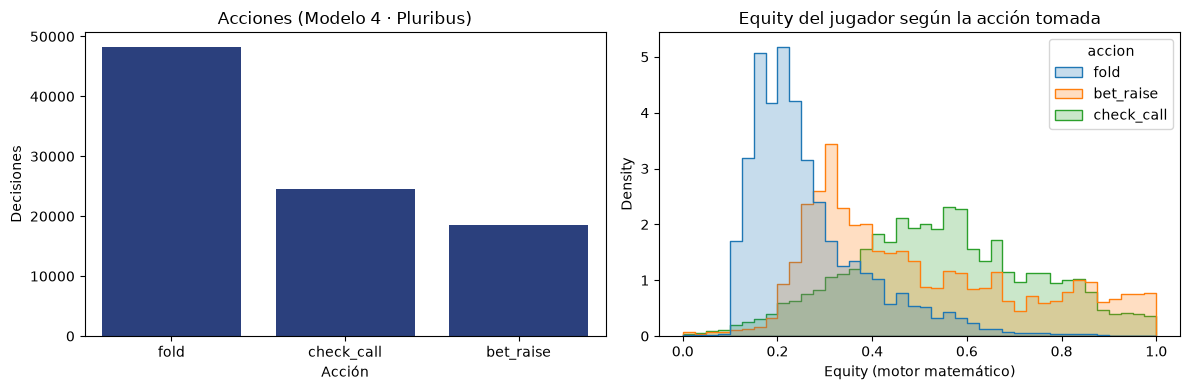

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

nombres_acciones = {0: 'fold', 1: 'check_call', 2: 'bet_raise'}
nombres_calles = {0: 'Preflop', 1: 'Flop', 2: 'Turn', 3: 'River'}

print("🎯 DECISIONES Y ACCIONES POR CONJUNTO:")
resumen = pd.crosstab(df_decisiones['split'], df_decisiones['accion'].map(nombres_acciones), normalize='index') * 100
resumen['decisiones'] = df_decisiones['split'].value_counts()
print(resumen.loc[['train', 'val', 'test']].round(2).to_string())

print("\n🃏 DECISIONES POR CALLE EN CADA CONJUNTO (el river es el más escaso):")
print(pd.crosstab(df_decisiones['calle'].map(nombres_calles), df_decisiones['split'])
      .reindex(list(nombres_calles.values()))[['train', 'val', 'test']].to_string())

print("\n🤖 HUMANOS VS PLURIBUS:")
for es_ia, grupo in df_decisiones.groupby('es_pluribus'):
    dist = grupo['accion'].map(nombres_acciones).value_counts(normalize=True) * 100
    print(f" • {'Pluribus' if es_ia else 'Profesionales':<14}: {len(grupo):,} decisiones | "
          f"fold {dist.get('fold', 0):.1f}% · call {dist.get('check_call', 0):.1f}% · raise {dist.get('bet_raise', 0):.1f}%")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.countplot(x=df_decisiones['accion'].map(nombres_acciones), order=['fold', 'check_call', 'bet_raise'], color='#1e3a8a')
plt.title('Acciones (Modelo 4 · Pluribus)'); plt.xlabel('Acción'); plt.ylabel('Decisiones')
plt.subplot(1, 2, 2)
sns.histplot(data=df_decisiones, x='c_equity', hue=df_decisiones['accion'].map(nombres_acciones),
             bins=40, stat='density', common_norm=False, element='step')
plt.title('Equity del jugador según la acción tomada'); plt.xlabel('Equity (motor matemático)')
plt.tight_layout()
os.makedirs('../informe/figuras', exist_ok=True)
plt.savefig('../informe/figuras/modelo4_distribuciones.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
print("=" * 70)
print("  🛡️ VERIFICACIONES ANTI-FUGA DE INFORMACIÓN (Doc. Maestro § 8.5)")
print("=" * 70)

# 1. Foto de la mesa coherente en todas las clases
enfrenta = df_decisiones[df_decisiones['to_call'] > 0]
coincide = (enfrenta['pot_odds'] - enfrenta['to_call'] / (enfrenta['bote'] + enfrenta['to_call'])).abs() < 0.0015
print("\n1. ¿La foto de la mesa es coherente (antes de actuar) en cada clase?")
print((pd.crosstab(coincide, enfrenta['accion'].map(nombres_acciones), normalize='columns') * 100).round(2).to_string())

# 2. Ninguna sesión compartida entre conjuntos
ses = {s: set(df_decisiones.loc[df_decisiones['split'] == s, 'sesion']) for s in ['train', 'val', 'test']}
print(f"\n2. Sesiones compartidas Train∩Val: {len(ses['train'] & ses['val'])} | Train∩Test: {len(ses['train'] & ses['test'])} | Val∩Test: {len(ses['val'] & ses['test'])}")

# 3. Solo cartas comunitarias ya repartidas
esperado = df_decisiones['calle'].map({0: 0, 1: 3, 2: 4, 3: 5})
print(f"3. Decisiones con cartas comunitarias de más o de menos (debe ser 0): {(df_decisiones['b_n'] != esperado).sum()}")

# 4. Las variables de cartas salen de las cartas PROPIAS del jugador
recalculo = df_decisiones['cartas'].map(lambda s: max(RANKS[s[0]], RANKS[s[2]]))
print(f"4. Decisiones cuya carta alta no coincide con sus propias cartas (debe ser 0): {(recalculo != df_decisiones['c_alta']).sum()}")

# 5. La mano que se guarda coincide con la que se repartió a ese jugador en el archivo original
control = 0
for mano in df_manos.head(500).itertuples(index=False):
    reparto = {a.split()[2]: a.split()[3] for a in mano.actions if a.startswith('d dh')}
    nombres = dict(zip([f"p{i+1}" for i in range(len(mano.players))], mano.players))
    filas = df_decisiones[df_decisiones['hand_key'] == mano.hand_key]
    control += sum(reparto[[p for p, nm in nombres.items() if nm == j][0]] != c for j, c in zip(filas['jugador'], filas['cartas']))
print(f"5. Cartas guardadas distintas a las repartidas al jugador (500 manos, debe ser 0): {control}")
print("=" * 70)

  🛡️ VERIFICACIONES ANTI-FUGA DE INFORMACIÓN (Doc. Maestro § 8.5)

1. ¿La foto de la mesa es coherente (antes de actuar) en cada clase?
accion  bet_raise  check_call   fold
row_0                               
True        100.0       100.0  100.0

2. Sesiones compartidas Train∩Val: 0 | Train∩Test: 0 | Val∩Test: 0
3. Decisiones con cartas comunitarias de más o de menos (debe ser 0): 0


4. Decisiones cuya carta alta no coincide con sus propias cartas (debe ser 0): 0


5. Cartas guardadas distintas a las repartidas al jugador (500 manos, debe ser 0): 0


In [8]:
print("💾 Guardando conjuntos en data/processed/modelo4/...")
for nombre_split in ['train', 'val', 'test']:
    parte = df_decisiones[df_decisiones['split'] == nombre_split].reset_index(drop=True)
    ruta = os.path.join(processed_dir, f"{nombre_split}.parquet")
    parte.to_parquet(ruta, index=False)
    print(f" • {nombre_split:<5}: {ruta} ➔ {os.path.getsize(ruta) / 1024**2:.1f} MB ({len(parte):,} decisiones)")
print("\n🎉 Fin del Notebook 08: datos del Modelo 4 listos para el entrenamiento.")

💾 Guardando conjuntos en data/processed/modelo4/...


 • train: ../data/processed/modelo4\train.parquet ➔ 1.5 MB (61,641 decisiones)
 • val  : ../data/processed/modelo4\val.parquet ➔ 0.4 MB (13,116 decisiones)
 • test : ../data/processed/modelo4\test.parquet ➔ 0.5 MB (16,599 decisiones)

🎉 Fin del Notebook 08: datos del Modelo 4 listos para el entrenamiento.
